# Fashion-MNIST con redes densas (Flatten)

Tarea: entrenar una red neuronal con `Flatten`, probar **3 configuraciones** distintas y comparar usando **accuracy**.

Dataset: **Fashion-MNIST** (70,000 imágenes 28×28 en escala de grises, 10 clases de ropa).

In [1]:
# Step 0: Importación de librerías
# Este notebook se ejecuta desde Kaggle Notebooks para poder usar gpu

import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

tf.random.set_seed(42)
np.random.seed(42)

gpus = tf.config.list_physical_devices('GPU')
print("GPUs:", gpus)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# Función auxiliar

def plot_learning_curve(history, titulo=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history['accuracy'], label='Training accuracy')
    axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
    axes[0].set_title(f'Accuracy - {titulo}')
    axes[0].set_xlabel('Época')
    axes[0].legend()

    axes[1].plot(history.history['loss'], label='Training loss')
    axes[1].plot(history.history['val_loss'], label='Validation loss')
    axes[1].set_title(f'Loss - {titulo}')
    axes[1].set_xlabel('Época')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## Step 1. Carga de datos

In [3]:
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

class_names = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
               "Sandalia", "Camisa", "Tenis", "Bolsa", "Botín"]

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.66SISU_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.66SISU_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.


Forma de un batch: (32, 28, 28, 1)


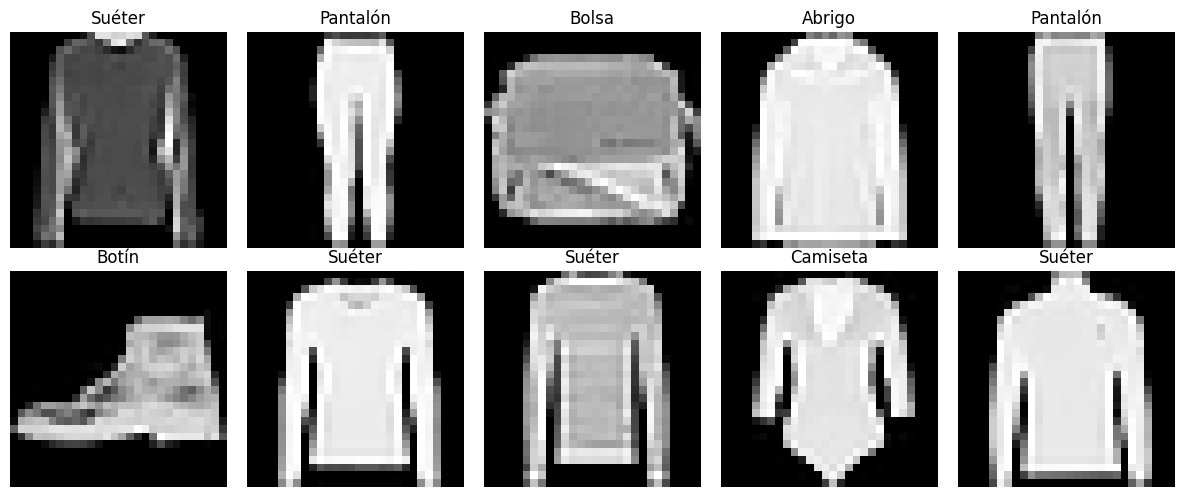

In [4]:
# Step 2: Visualizar imágenes de ejemplo (cada imagen es una matriz 2D de 28x28)
imgs, labels = next(iter(train_ds))
print("Forma de un batch:", imgs.shape)   # (32, 28, 28, 1)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(imgs[i].numpy().squeeze(), cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 3. Preprocesamiento
Normalizamos los pixeles a [0, 1].

In [5]:
def normalizar(x, y):
    return tf.cast(x, tf.float32) / 255.0, y

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(normalizar, num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)
test_ds  = test_ds.map(normalizar,  num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)

INPUT_SHAPE = (28, 28, 1)
EPOCHS = 15

## Step 4. Configuraciones

| Config | Arquitectura | Regularización | Optimizador |
|---|---|---|---|
| A | Flatten → 128 → 10 | — | Adam (lr=1e-3) |
| B | Flatten → 256 → 128 → 10 | Dropout 0.3 | Adam (lr=1e-3) |
| C | Flatten → 512 → 256 → 128 → 10 | BatchNorm + Dropout 0.3 | SGD + momentum (lr=1e-2) |

In [6]:
# Configuraciones a usar

def config_a():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=INPUT_SHAPE),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ], name="A_simple"), tf.keras.optimizers.Adam(1e-3)

def config_b():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=INPUT_SHAPE),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(10, activation="softmax"),
    ], name="B_dropout"), tf.keras.optimizers.Adam(1e-3)

def config_c():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=INPUT_SHAPE),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512), tf.keras.layers.BatchNormalization(), tf.keras.layers.Activation("relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(256), tf.keras.layers.BatchNormalization(), tf.keras.layers.Activation("relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(128), tf.keras.layers.BatchNormalization(), tf.keras.layers.Activation("relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ], name="C_profunda_bn"), tf.keras.optimizers.SGD(1e-2, momentum=0.9)

configs = {"A": config_a, "B": config_b, "C": config_c}

## Step 5. Entrenamiento

Se entrenarán los modelos de forma secuencial en una sola iteración. El proceso tardará algunos minutos. No se recomienda correrlo en CPU.


===== Configuración A =====
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Model: "A_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1875/1875 - 10s - 5ms/step - accuracy: 0.8234 - loss: 0.5003 - val_accuracy: 0.8372 - val_loss: 0.4498
Epoch 2/15
1875/1875 - 4s - 2ms/step - accuracy: 0.8648 - loss: 0.3755 - val_accuracy: 0.8572 - val_loss: 0.3977
Epoch 3/15
1875/1875 - 4s - 2ms/step - accuracy: 0.8788 - loss: 0.3344 - val_accuracy: 0.8644 - val_loss: 0.3775
Epoch 4/15
1875/1875 - 4s - 2ms/step - accuracy: 0.8874 - loss: 0.3092 - val_accuracy: 0.8690 - val_loss: 0.3637
Epoch 5/15
1875/1875 - 4s - 2ms/step - accuracy: 0.8933 - loss: 0.2899 - val_accuracy: 0.8755 - val_loss: 0.3454
Epoch 6/15
1875/1875 - 4s - 2ms/step - accuracy: 0.8988 - loss: 0.2738 - val_accuracy: 0.8779 - val_loss: 0.3414
Epoch 7/15
1875/1875 - 4s - 2ms/step - accuracy: 0.9028 - loss: 0.2605 - val_accuracy: 0.8788 - val_loss: 0.3422
Epoch 8/15
1875/1875 - 4s - 2ms/step - accuracy: 0.9083 - loss: 0.2481 - val_accuracy: 0.8819 - val_loss: 0.3403
Epoch 9/15
1875/1875 - 4s - 2ms/step - accuracy: 0.9119 - loss: 0.2382 - val_accuracy: 0.8831 -

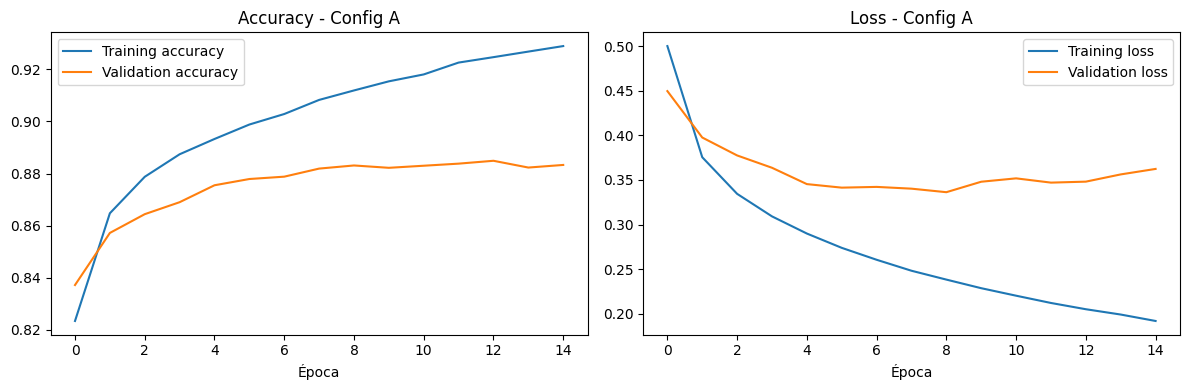


===== Configuración B =====


Model: "B_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1875/1875 - 8s - 4ms/step - accuracy: 0.7944 - loss: 0.5703 - val_accuracy: 0.8405 - val_loss: 0.4501
Epoch 2/15
1875/1875 - 5s - 2ms/step - accuracy: 0.8436 - loss: 0.4317 - val_accuracy: 0.8569 - val_loss: 0.4066
Epoch 3/15
1875/1875 - 4s - 2ms/step - accuracy: 0.8538 - loss: 0.4000 - val_accuracy: 0.8641 - val_loss: 0.3779
Epoch 4/15
1875/1875 - 4s - 2ms/step - accuracy: 0.8628 - loss: 0.3783 - val_accuracy: 0.8675 - val_loss: 0.3654
Epoch 5/15
1875/1875 - 5s - 2ms/step - accuracy: 0.8663 - loss: 0.3630 - val_accuracy: 0.8662 - val_loss: 0.3743
Epoch 6/15
1875/1875 - 5s - 2ms/step - accuracy: 0.8720 - loss: 0.3469 - val_accuracy: 0.8724 - val_loss: 0.3578
Epoch 7/15
1875/1875 - 5s - 2ms/step - accuracy: 0.8748 - loss: 0.3409 - val_accuracy: 0.8686 - val_loss: 0.3693
Epoch 8/15
1875/1875 - 5s - 2ms/step - accuracy: 0.8777 - loss: 0.3308 - val_accuracy: 0.8780 - val_loss: 0.3495
Epoch 9/15
1875/1875 - 5s - 2ms/step - accuracy: 0.8820 - loss: 0.3201 - val_accuracy: 0.8745 - 

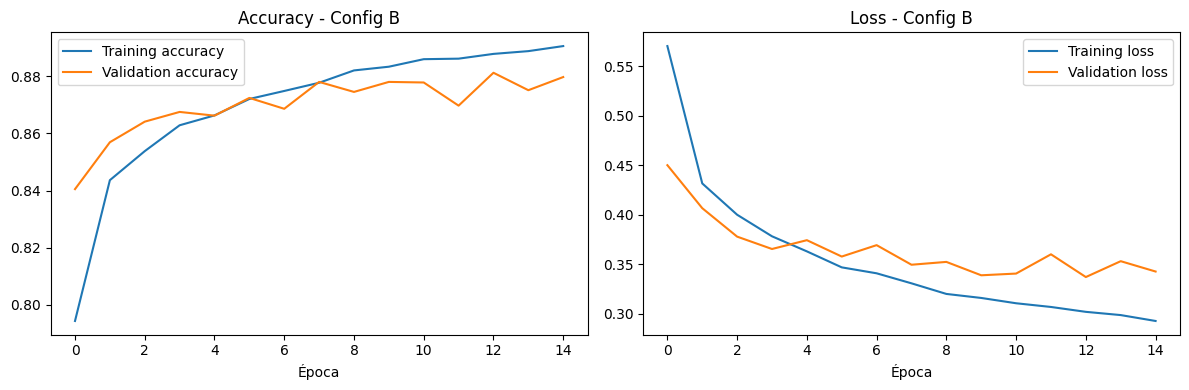


===== Configuración C =====


Model: "C_profunda_bn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 571,018 (2.18 MB)

 Trainable params: 569,226 (2.17 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/15
1875/1875 - 9s - 5ms/step - accuracy: 0.8031 - loss: 0.5490 - val_accuracy: 0.8364 - val_loss: 0.4520
Epoch 2/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8493 - loss: 0.4199 - val_accuracy: 0.8589 - val_loss: 0.3987
Epoch 3/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8613 - loss: 0.3771 - val_accuracy: 0.8598 - val_loss: 0.3847
Epoch 4/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8704 - loss: 0.3531 - val_accuracy: 0.8693 - val_loss: 0.3790
Epoch 5/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8765 - loss: 0.3333 - val_accuracy: 0.8752 - val_loss: 0.3492
Epoch 6/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8834 - loss: 0.3173 - val_accuracy: 0.8739 - val_loss: 0.3545
Epoch 7/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8878 - loss: 0.3022 - val_accuracy: 0.8732 - val_loss: 0.3596
Epoch 8/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8920 - loss: 0.2899 - val_accuracy: 0.8750 - val_loss: 0.3531
Epoch 9/15
1875/1875 - 5s - 3ms/step - accuracy: 0.8965 - loss: 0.2787 - val_accuracy: 0.8783 - 

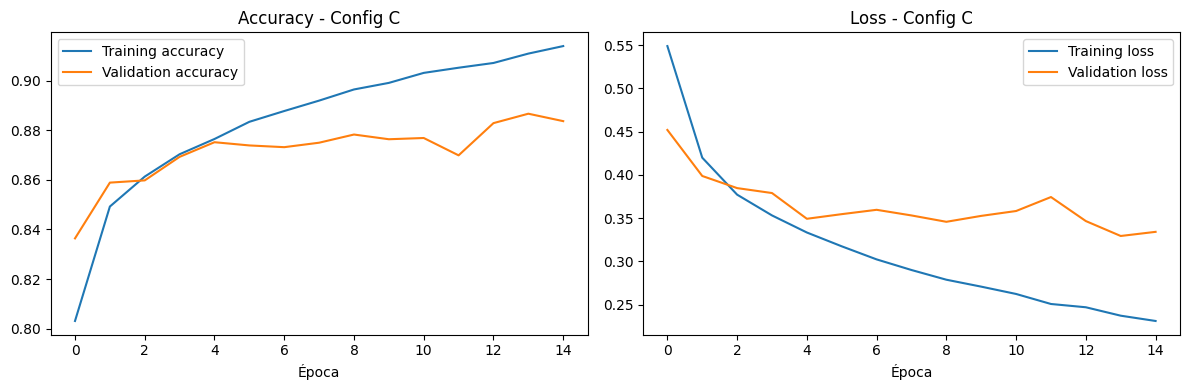

In [7]:
modelos, historias, resultados = {}, {}, {}

for nombre, builder in configs.items():
    print(f"\n===== Configuración {nombre} =====")
    model, opt = builder()
    model.compile(optimizer=opt,
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    model.summary()

    history = model.fit(train_ds, epochs=EPOCHS, validation_data=test_ds, verbose=2)
    _, acc = model.evaluate(test_ds, verbose=0)

    modelos[nombre], historias[nombre], resultados[nombre] = model, history, acc
    print(f"Accuracy en test ({nombre}): {acc:.4f}")
    plot_learning_curve(history, f"Config {nombre}")

## Step 6. Comparación de accuracy

Config A: test acc = 0.8833 | parámetros = 101,770
Config B: test acc = 0.8797 | parámetros = 235,146
Config C: test acc = 0.8837 | parámetros = 571,018


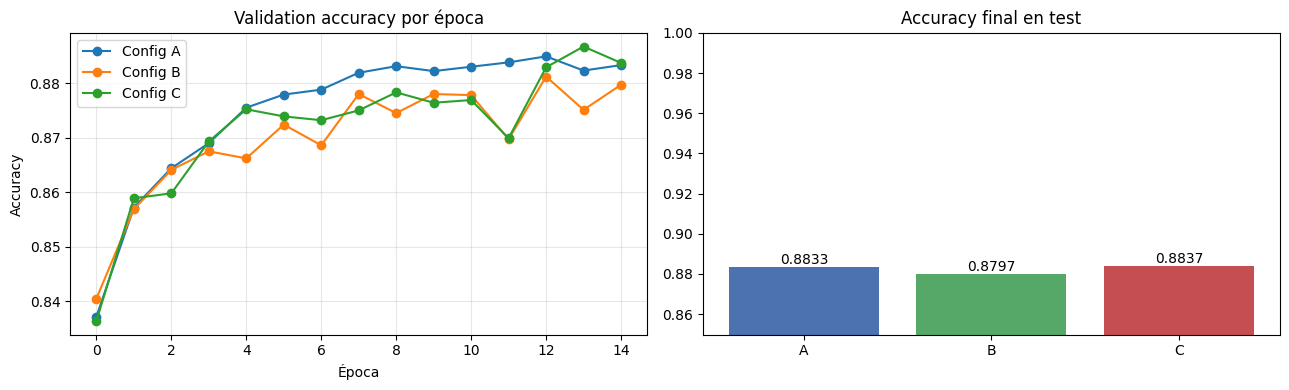

In [8]:
for n in configs:
    print(f"Config {n}: test acc = {resultados[n]:.4f} | parámetros = {modelos[n].count_params():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in configs:
    axes[0].plot(historias[n].history['val_accuracy'], marker="o", label=f"Config {n}")
axes[0].set_title("Validation accuracy por época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)

bars = axes[1].bar(list(resultados), list(resultados.values()), color=["#4C72B0", "#55A868", "#C44E52"])
axes[1].bar_label(bars, fmt="%.4f")
axes[1].set_ylim(min(resultados.values()) - 0.03, 1.0)
axes[1].set_title("Accuracy final en test")
plt.tight_layout()
plt.show()

## Step 7. Análisis del mejor modelo

Mejor configuración: C


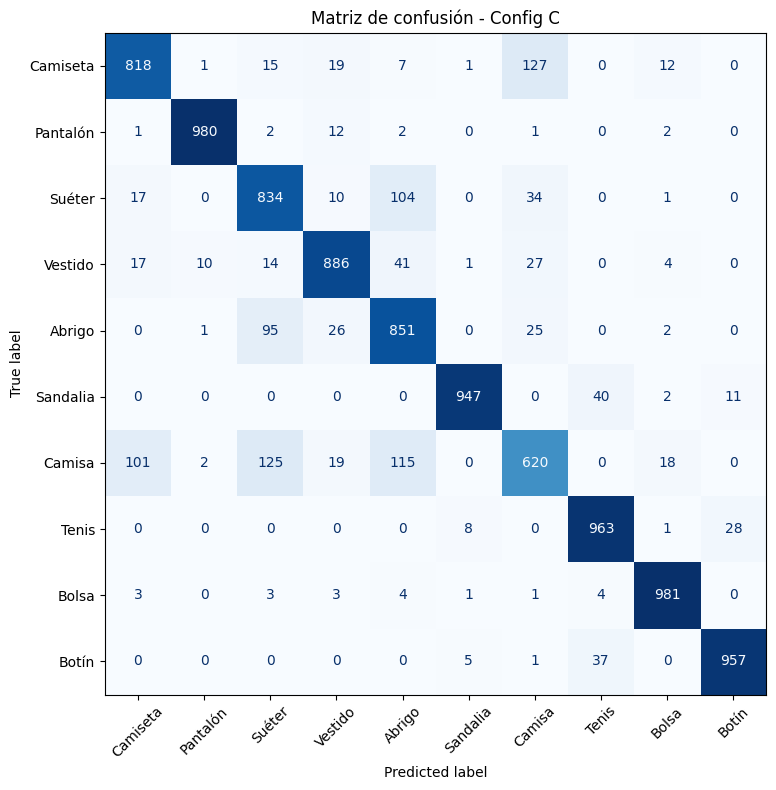

In [9]:
mejor = max(resultados, key=resultados.get)
best_model = modelos[mejor]
print("Mejor configuración:", mejor)

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(best_model.predict(test_ds, verbose=0), axis=1)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión - Config {mejor}")
plt.tight_layout()
plt.show()

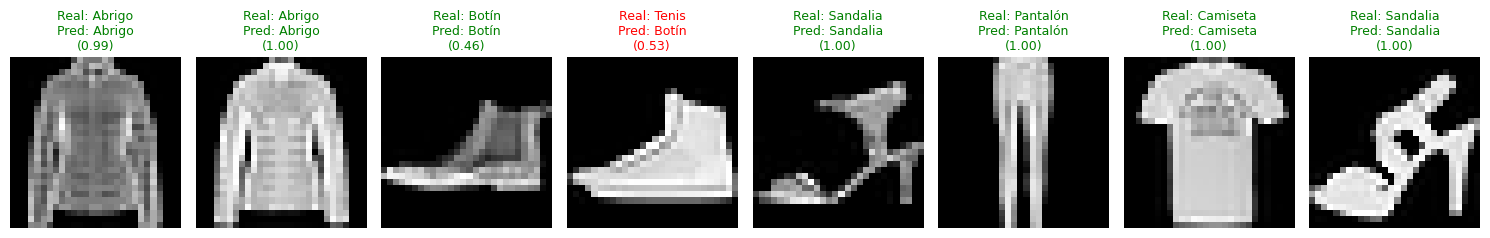

In [10]:
# Step 8: Predicciones de ejemplo
imgs, labels = next(iter(test_ds))
preds = best_model.predict(imgs, verbose=0)

plt.figure(figsize=(15, 4))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(imgs[i].numpy().squeeze(), cmap="gray")
    p = np.argmax(preds[i])
    color = "green" if p == labels[i] else "red"
    plt.title(f"Real: {class_names[labels[i]]}\nPred: {class_names[p]}\n({preds[i][p]:.2f})", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 9: Visualización 2D de lo que aprendió la red

Tomamos la salida de la última capa oculta y la proyectamos a 2D con PCA. Si la red separa bien las clases, se forman grupos por color.

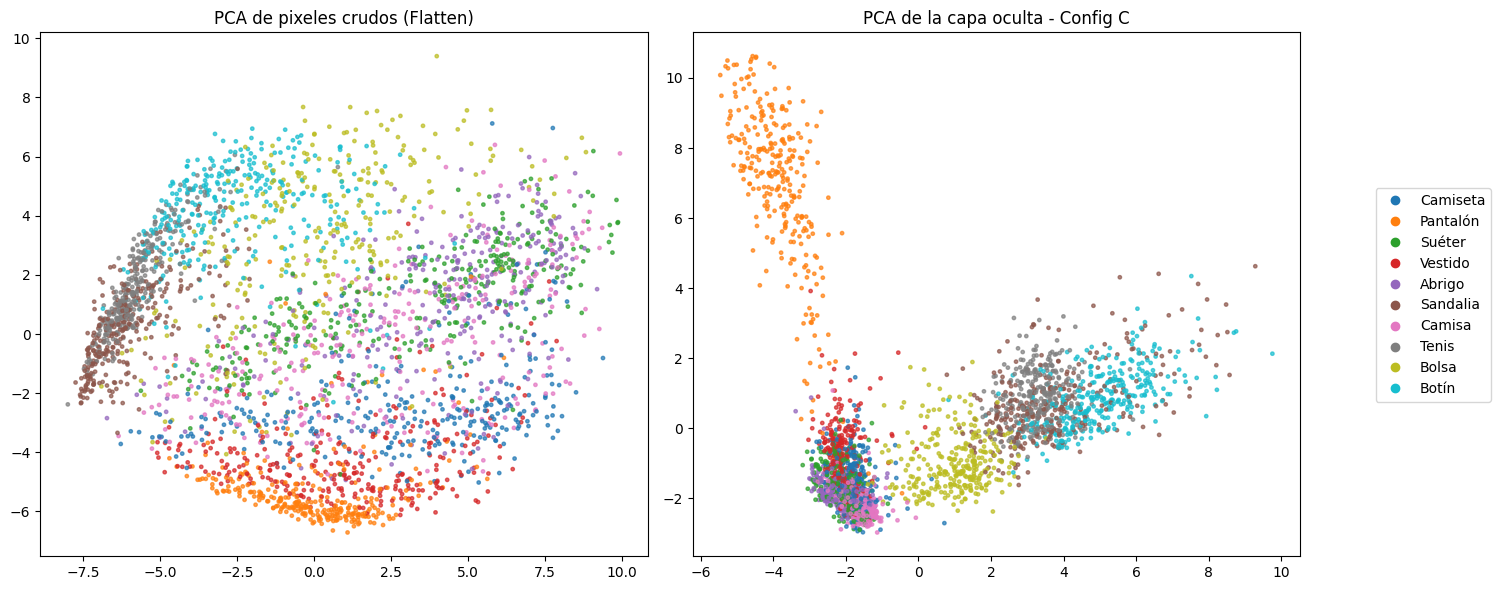

In [11]:
# Modelo que devuelve la penúltima capa (embedding)
embedder = tf.keras.Model(inputs=best_model.inputs, outputs=best_model.layers[-2].output)

N = 3000
x_sub = np.concatenate([x.numpy() for x, _ in test_ds])[:N]
y_sub = y_true[:N]

emb = embedder.predict(x_sub, verbose=0)
emb_2d = PCA(n_components=2).fit_transform(emb)
raw_2d = PCA(n_components=2).fit_transform(x_sub.reshape(N, -1))   # pixeles crudos (solo Flatten)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, titulo in [(axes[0], raw_2d, "PCA de pixeles crudos (Flatten)"),
                         (axes[1], emb_2d, f"PCA de la capa oculta - Config {mejor}")]:
    sc = ax.scatter(data[:, 0], data[:, 1], c=y_sub, cmap="tab10", s=6, alpha=0.7)
    ax.set_title(titulo)
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i / 9), label=class_names[i]) for i in range(10)]
fig.legend(handles=handles, loc="center right")
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

## Conclusiones

- La configuración A es la mejor al obtener un accuracy en test de 88% con menos parámetros
- Clases que más se confunden: normalmente **Camisa vs Camiseta/Suéter/Abrigo**, porque al aplanar la imagen se pierde la estructura espacial.